In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

datasetPath = "../data/Intel_Image_Classification/data_classifier"

def explorationPreparation():
    
    totalImage = 0
    data = []
    for classe in os.listdir(datasetPath):
            chemin = os.path.join(datasetPath, classe)
            if os.path.isdir(chemin):
                images = os.listdir(chemin)
                totalImage += len(images)
    
    for classe in os.listdir(datasetPath):
        chemin = os.path.join(datasetPath, classe)
        if os.path.isdir(chemin):
            images = os.listdir(chemin)
            prc = (len(images) / totalImage) * 100
            data.append({"classe": classe,
                        "porcentage": prc,
                        "totalImage": len(images)})
    return data
explorationPreparation()


def getImagesClasse():
    data = []

    for classe in os.listdir(datasetPath):
        chemin = os.path.join(datasetPath, classe)

        if os.path.isdir(chemin):
            images = []

            for image in os.listdir(chemin):
                chemin_image = os.path.join(chemin, image)

                if os.path.isfile(chemin_image):
                    images.append(chemin_image)

            data.append({
                "classe": classe,
                "images": images
            })

    return data
print(getImagesClasse())

[{'classe': 'buildings', 'images': ['../data/Intel_Image_Classification/data_classifier\\buildings\\0.jpg', '../data/Intel_Image_Classification/data_classifier\\buildings\\10006.jpg', '../data/Intel_Image_Classification/data_classifier\\buildings\\1001.jpg', '../data/Intel_Image_Classification/data_classifier\\buildings\\10014.jpg', '../data/Intel_Image_Classification/data_classifier\\buildings\\10018.jpg', '../data/Intel_Image_Classification/data_classifier\\buildings\\10029.jpg', '../data/Intel_Image_Classification/data_classifier\\buildings\\10032.jpg', '../data/Intel_Image_Classification/data_classifier\\buildings\\10056.jpg', '../data/Intel_Image_Classification/data_classifier\\buildings\\1009.jpg', '../data/Intel_Image_Classification/data_classifier\\buildings\\10113.jpg', '../data/Intel_Image_Classification/data_classifier\\buildings\\1012.jpg', '../data/Intel_Image_Classification/data_classifier\\buildings\\10126.jpg', '../data/Intel_Image_Classification/data_classifier\\buildi

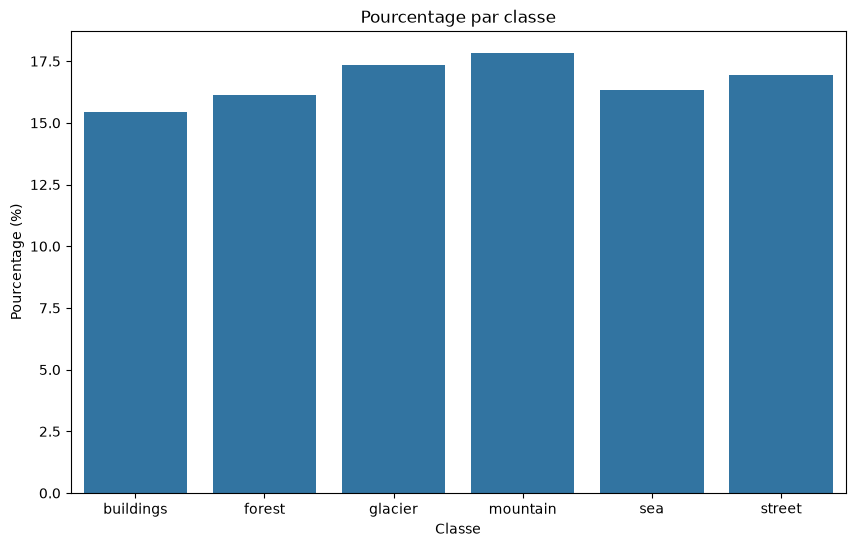

In [25]:
data = explorationPreparation()
df = pd.DataFrame(data)
plt.figure(figsize=(10, 6))

sns.barplot(
        data=df,
        x="classe",
        y="porcentage"
)

plt.title("Pourcentage par classe")
plt.xlabel("Classe")
plt.ylabel("Pourcentage (%)")

plt.show()

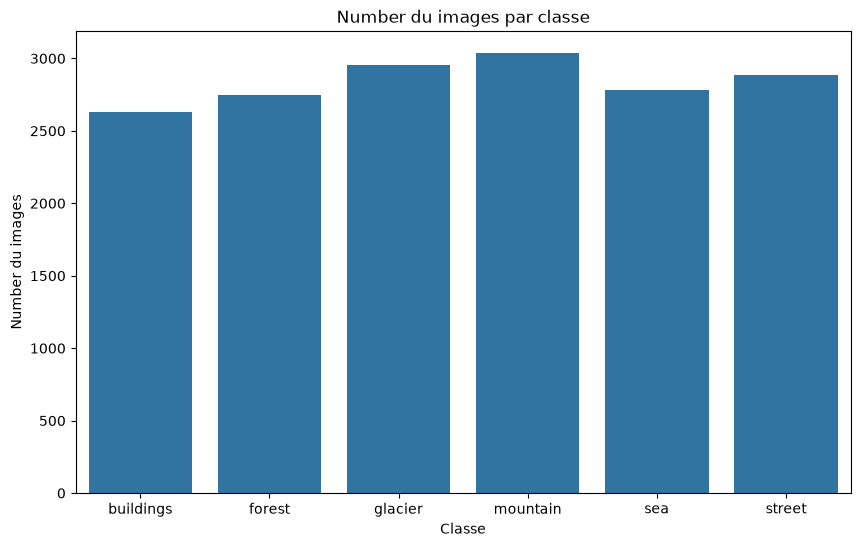

In [26]:
data = explorationPreparation()
df = pd.DataFrame(data)
plt.figure(figsize=(10, 6))

sns.barplot(
        data=df,
        x="classe",
        y="totalImage"
)

plt.title("Number du images par classe")
plt.xlabel("Classe")
plt.ylabel("Number du images")

plt.show()

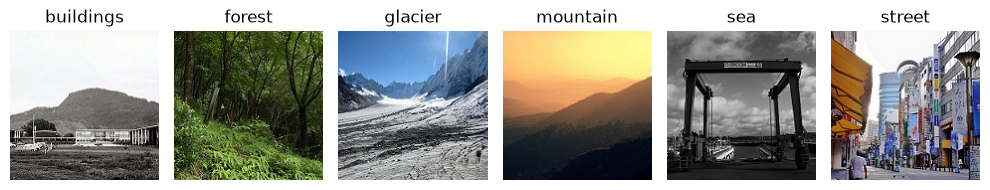

In [27]:
from PIL import Image

imagesData = getImagesClasse()

plt.figure(figsize=(10, 6))
for i, item in enumerate(imagesData):

    image = Image.open(item["images"][0])
    plt.subplot(1, len(data), i + 1)
    plt.imshow(image)
    plt.title(item["classe"])
    plt.axis("off")

plt.tight_layout()
plt.show()
        


In [28]:
from collections import Counter

imagesData = getImagesClasse()

for item in imagesData:
    dimensions = Counter()
    formats = Counter()
    modes = Counter()
    erreurs = 0
    for chemin_image in item["images"]:
        try:
            with Image.open(chemin_image) as image:
                dimensions[image.size] += 1
                formats[image.format] += 1
                modes[image.mode] += 1 
        except Exception:
            erreurs += 1
    print(f"\nClasse : {item['classe']}")
    print("Dimensions :", dimensions)
    print("Formats :", formats)
    print("Modes :", modes)
    print("Images illisibles :", erreurs)



Classe : buildings
Dimensions : Counter({(150, 150): 2627, (150, 124): 1})
Formats : Counter({'JPEG': 2628})
Modes : Counter({'RGB': 2628})
Images illisibles : 0

Classe : forest
Dimensions : Counter({(150, 150): 2736, (150, 113): 2, (150, 108): 2, (150, 133): 1, (150, 115): 1, (150, 135): 1, (150, 141): 1, (150, 136): 1})
Formats : Counter({'JPEG': 2745})
Modes : Counter({'RGB': 2745})
Images illisibles : 0

Classe : glacier
Dimensions : Counter({(150, 150): 2936, (150, 111): 3, (150, 110): 2, (150, 149): 2, (150, 76): 2, (150, 105): 1, (150, 120): 1, (150, 143): 1, (150, 146): 1, (150, 134): 1, (150, 142): 1, (150, 123): 1, (150, 119): 1, (150, 102): 1, (150, 72): 1, (150, 97): 1, (150, 135): 1})
Formats : Counter({'JPEG': 2957})
Modes : Counter({'RGB': 2957})
Images illisibles : 0

Classe : mountain
Dimensions : Counter({(150, 150): 3018, (150, 144): 2, (150, 131): 2, (150, 81): 2, (150, 134): 1, (150, 135): 1, (150, 123): 1, (150, 113): 1, (150, 142): 1, (150, 103): 1, (150, 136):

In [29]:
import hashlib
from collections import defaultdict, Counter

imagesData = getImagesClasse()

MIN_WIDTH = 100
MIN_HEIGHT = 100

duplicates = []
too_small = []
same_color = defaultdict(list)
erreurs = 0

hashes = {}

for item in imagesData:
    classe = item["classe"]
    for chemin_image in item["images"]:
        try:
            with Image.open(chemin_image) as image:
                width, height = image.size

                if width < MIN_WIDTH or height < MIN_HEIGHT:
                    too_small.append({
                        "classe": classe,
                        "chemin": chemin_image,
                        "dimensions": image.size
                    })

                with open(chemin_image, "rb") as fichier:
                        contenu = fichier.read()
                        hash_image = hashlib.md5(contenu).hexdigest()

                if hash_image in hashes:
                    duplicates.append({
                        "originale": hashes[hash_image],
                        "doublon": chemin_image
                    })
                else:
                    hashes[hash_image] = chemin_image

                image_rgb = image.convert("RGB")
                image_reduite = image_rgb.resize((50, 50))
                couleur = image_reduite.quantize(
                    colors=1
                ).convert("RGB").getpixel((0, 0))

                same_color[couleur].append({
                    "classe": classe,
                    "chemin": chemin_image
                })

        except Exception:
            erreurs += 1

print("Nombre de doublons :", len(duplicates))
print("Nombre d'images trop petites :", len(too_small))
print("Nombre de groupes de couleurs identiques :",
      sum(1 for images in same_color.values() if len(images) > 1))
print("Nombre d'erreurs :", erreurs)

print("\n--- DOUBLONS ---")
for item in duplicates[:10]:
    print("Originale :", item["originale"])
    print("Doublon   :", item["doublon"])
    print()

Nombre de doublons : 18
Nombre d'images trop petites : 6
Nombre de groupes de couleurs identiques : 970
Nombre d'erreurs : 0

--- DOUBLONS ---
Originale : ../data/Intel_Image_Classification/data_classifier\forest\15657.jpg
Doublon   : ../data/Intel_Image_Classification/data_classifier\forest\18807.jpg

Originale : ../data/Intel_Image_Classification/data_classifier\forest\8688.jpg
Doublon   : ../data/Intel_Image_Classification/data_classifier\forest\8689.jpg

Originale : ../data/Intel_Image_Classification/data_classifier\glacier\21469.jpg
Doublon   : ../data/Intel_Image_Classification/data_classifier\mountain\14341.jpg

Originale : ../data/Intel_Image_Classification/data_classifier\glacier\16827.jpg
Doublon   : ../data/Intel_Image_Classification/data_classifier\mountain\15770.jpg

Originale : ../data/Intel_Image_Classification/data_classifier\glacier\8191.jpg
Doublon   : ../data/Intel_Image_Classification/data_classifier\mountain\16696.jpg

Originale : ../data/Intel_Image_Classification

In [30]:
from sklearn.model_selection import train_test_split

imagesData = getImagesClasse()
X = []
y = []
for item in imagesData:
    for chemin_image in item["images"]:
        X.append(chemin_image)
        y.append(item["classe"])


# train 
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# validation 
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train :", len(X_train))
print("Validation :", len(X_val))
print("Test :", len(X_test))

Train : 11923
Validation : 2555
Test : 2556


In [31]:
import tensorflow as tf


train_ds = tf.keras.utils.image_dataset_from_directory(
    datasetPath,
    image_size=(150, 150),
    batch_size=32,
    shuffle=True,
    seed=42
)

normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda images, labels: (
        normalization_layer(images),
        labels
    )
)


for images, labels in train_ds.take(1):
    print("Forme des images :", images.shape)
    print("Forme des labels :", labels.shape)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(
    buffer_size=AUTOTUNE
)


Found 17034 files belonging to 6 classes.
Forme des images : (32, 150, 150, 3)
Forme des labels : (32,)


In [32]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    datasetPath,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(150, 150),
    batch_size=32
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    datasetPath,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(150, 150),
    batch_size=32
)

Found 17034 files belonging to 6 classes.
Using 13628 files for training.
Found 17034 files belonging to 6 classes.
Using 3406 files for validation.


In [33]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
])

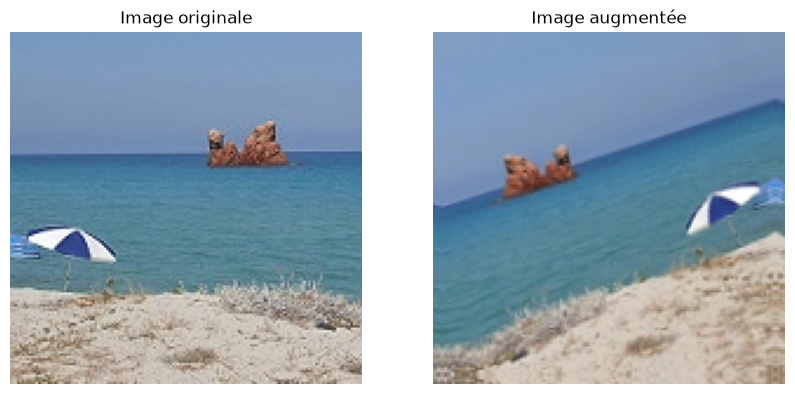

In [45]:
for images, labels in train_ds.take(1):
    image = images[0]

    augmented_image = data_augmentation(
        tf.expand_dims(image, axis=0),
        training=True
    )[0]

    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(image.numpy().astype("uint8"))
    plt.title("Image originale")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(
        tf.clip_by_value(augmented_image, 0, 255).numpy().astype("uint8")
    )
    plt.title("Image augmentée")
    plt.axis("off")

    plt.show()

In [47]:
from tensorflow.keras import layers, models

num_classes = 6

image_size = (150, 150, 3)

model = models.Sequential([

    layers.Input(shape=image_size),

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), padding="same"),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same"),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),

 
    layers.Conv2D(128, (3, 3), padding="same"),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),

    
    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_4 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,402,566 (20.61 MB)

 Trainable params: 5,402,566 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

In [48]:
print("Version TensorFlow :", tf.__version__)

print("GPU disponibles :")
print(tf.config.list_physical_devices("GPU"))

print("CPU disponibles :")
print(tf.config.list_physical_devices("CPU"))

Version TensorFlow : 2.21.0
GPU disponibles :
[]
CPU disponibles :
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
